# 01. Выгрузка и подготовка данных — Jigsaw Unintended Bias in Toxicity Classification

**Перед запуском (один раз):**
1. Зайти на страницу соревнования https://www.kaggle.com/c/jigsaw-unintended-bias-in-toxicity-classification → вкладка *Data* / *Rules* → нажать **I Understand and Accept**. Без этого `competition_download` вернёт 403.
2. Токен Kaggle (Settings → API → *Generate New Token*) вставить в файл `.env` в этой папке:
   `KAGGLE_API_TOKEN=ваш_токен`. Файл `.env` в `.gitignore`, в git он не попадёт.
3. После правки `.env` перезапустить ядро (Kernel → Restart) и выполнить ячейки сверху.

Ноутбук: скачивает данные → смотрит на поля → чистит тексты → делит на страты (явно токсичные / явно нетоксичные / спорные) → сохраняет пул соседей и целевые тексты в `data/processed/`.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import kagglehub

SEED = 42
rng = np.random.default_rng(SEED)

PROJECT_DIR = Path.cwd()
DATA_RAW = PROJECT_DIR / "data" / "raw"         
DATA_PROC = PROJECT_DIR / "data" / "processed"
DATA_RAW.mkdir(parents=True, exist_ok=True)
DATA_PROC.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_colwidth", 200)

In [2]:
from dotenv import load_dotenv
import os

if (DATA_RAW / "train.csv").exists():
    path = str(DATA_RAW)
else:
    load_dotenv(PROJECT_DIR / ".env", override=True)
    assert os.getenv("KAGGLE_API_TOKEN")
    path = kagglehub.competition_download(
        'jigsaw-unintended-bias-in-toxicity-classification',
        output_dir=str(DATA_RAW),  
    )

print("Path to competition files:", path)
RAW_DIR = Path(path)

Path to competition files: d:\statia\data\raw


In [3]:
for f in sorted(RAW_DIR.glob("*")):
    if f.is_file():
        print(f"{f.relative_to(RAW_DIR)!s:55} {f.stat().st_size/1e6:9.1f} MB")

all_data.csv                                                916.1 MB
identity_individual_annotations.csv                         106.4 MB
sample_submission.csv                                         1.2 MB
test.csv                                                     29.9 MB
test_private_expanded.csv                                    44.1 MB
test_public_expanded.csv                                     44.3 MB
toxicity_individual_annotations.csv                         417.6 MB
train.csv                                                   816.2 MB


## Какие поля берём из `train.csv`

| Поле | Зачем |
|---|---|
| `id` | ключ, связь с индивидуальной разметкой |
| `comment_text` | сам текст (целевой и соседи) |
| `target` | доля разметчиков, посчитавших текст токсичным (0–1) → бинарная метка (`>= 0.5`) и степень спорности (H2) |
| `toxicity_annotator_count` | сколько людей размечало; отсекаем тексты с малым числом разметчиков, иначе `target` шумный |
| `severe_toxicity`, `obscene`, `identity_attack`, `insult`, `threat`, `sexual_explicit` | подтипы токсичности — контроль: соседи не должны отличаться от целевого текста «типом» токсичности |
| `article_id` | чтобы сосед и целевой текст не были из одного обсуждения (иначе тексты связаны по смыслу) |


In [4]:
MIN_ANNOTATORS = 10

TRAIN_COLS = [
    "id", "comment_text", "target", "toxicity_annotator_count",
    "severe_toxicity", "obscene", "identity_attack", "insult", "threat", "sexual_explicit",
    "article_id",
]
DTYPES = {
    "id": "int32", "target": "float32", "toxicity_annotator_count": "int16", "article_id": "int32",
    "severe_toxicity": "float32", "obscene": "float32", "identity_attack": "float32",
    "insult": "float32", "threat": "float32", "sexual_explicit": "float32",
}

train_path = RAW_DIR / "train.csv"
stats, parts = [], []
for chunk in pd.read_csv(train_path, usecols=TRAIN_COLS, dtype=DTYPES, chunksize=200_000):
    stats.append(chunk[["target", "toxicity_annotator_count"]])
    parts.append(chunk[chunk["toxicity_annotator_count"] >= MIN_ANNOTATORS])
stats = pd.concat(stats, ignore_index=True)
df = pd.concat(parts, ignore_index=True)
del parts

print(f"всего в train: {len(stats):,}; с >= {MIN_ANNOTATORS} разметчиками: {len(df):,}")
df.head()

всего в train: 1,804,874; с >= 10 разметчиками: 339,399


,id,target,comment_text,severe_toxicity,obscene,identity_attack,insult,threat,article_id,sexual_explicit,toxicity_annotator_count
0,59856,0.893617,haha you guys are a bunch of losers.,0.021277,0.000000,0.021277,0.872340,0.0,2006,0.000000,47
1,59859,0.666667,ur a sh*tty comment.,0.047619,0.638095,0.000000,0.333333,0.0,2006,0.009524,105
2,59861,0.457627,hahahahahahahahhha suck it.,0.050847,0.305085,0.000000,0.254237,0.0,2006,0.220339,59
3,239579,0.440000,"This is a great story. Man. I wonder if the person who yelled ""shut the fuck up!"" at him ever heard it.",0.000000,0.293333,0.000000,0.320000,0.0,26650,0.040000,75
4,239583,0.600000,"It's ridiculous that these guys are being called ""protesters"". Being armed is a threat of violence, which makes them terrorists.",0.000000,0.100000,0.000000,0.600000,0.1,26670,0.000000,10


In [5]:
print(stats["target"].describe())
print("\nДоля токсичных (target >= 0.5):", round((stats["target"] >= 0.5).mean(), 4))
print("\nЧисло разметчиков на текст:")
print(stats["toxicity_annotator_count"].describe(percentiles=[.25, .5, .75, .9, .99]))
print("\nДоля токсичных среди текстов с >= MIN_ANNOTATORS:", round((df["target"] >= 0.5).mean(), 4))

count    1.804874e+06
mean     1.030173e-01
std      1.970757e-01
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      1.666667e-01
max      1.000000e+00
Name: target, dtype: float64

Доля токсичных (target >= 0.5): 0.08

Число разметчиков на текст:
count    1.804874e+06
mean     8.784694e+00
std      4.350086e+01
min      3.000000e+00
25%      4.000000e+00
50%      4.000000e+00
75%      6.000000e+00
90%      1.000000e+01
99%      7.500000e+01
max      4.936000e+03
Name: toxicity_annotator_count, dtype: float64

Доля токсичных среди текстов с >= MIN_ANNOTATORS: 0.3991


## Индивидуальная разметка (для H2: насколько разметчики разошлись)

`toxicity_individual_annotations.csv` — по строке на пару (текст, разметчик). Сначала смотрим, какие там значения, потом считаем долю «токсично» по каждому тексту и сверяем с `target`.

In [6]:
# Индивидуальная разметка (~420 МБ): тоже частями, оставляем только строки по текстам из df
ind_path = RAW_DIR / "toxicity_individual_annotations.csv"
if not ind_path.exists():
    print("Файла с индивидуальной разметкой нет — спорность считаем только по target")
    ind = None
else:
    keep_ids = set(df["id"])
    parts = []
    for chunk in pd.read_csv(ind_path, usecols=["id", "worker", "toxic"],
                             dtype={"id": "int32", "worker": "int32", "toxic": "int8"},
                             chunksize=2_000_000):
        parts.append(chunk[chunk["id"].isin(keep_ids)])
    ind = pd.concat(parts, ignore_index=True)
    del parts
    print(ind.shape)
    print(ind["toxic"].value_counts().sort_index())

(9497048, 3)
toxic
0    4441242
1    5055806
Name: count, dtype: int64


In [7]:
if ind is not None:
    agg = (ind.assign(is_toxic=(ind["toxic"] > 0).astype(int))
              .groupby("id")
              .agg(n_workers=("worker", "nunique"), share_toxic=("is_toxic", "mean"))
              .reset_index())
    df = df.merge(agg, on="id", how="left")
    # sanity-check: доля по индивидуальной разметке должна почти совпадать с target
    print(df[["target", "share_toxic"]].corr())

             target  share_toxic
target          1.0          1.0
share_toxic     1.0          1.0


## Очистка и фильтры

- нормализуем пробелы/переносы строк;
- убираем пустые, дубли и тексты со ссылками;
- оставляем тексты, где разметчиков `>= MIN_ANNOTATORS` (иначе доля 0.5 может значить «1 из 2»);
- ограничиваем длину `MIN_WORDS..MAX_WORDS` — чтобы батч из 9 текстов был умеренной длины и соседей было легко подобрать по длине (±15%).

Пороги — параметры, их можно менять после просмотра распределений.

In [8]:
MIN_WORDS, MAX_WORDS = 15, 60

def normalize(text: str) -> str:
    text = str(text).replace("\r", " ").replace("\n", " ")
    return re.sub(r"\s+", " ", text).strip()

df["text"] = df["comment_text"].map(normalize)
df["n_words"] = df["text"].str.split().str.len()

# Мусор: спам декоративными юникод-символами (ᴍʏ Fʀɪᴇɴᴅ…, 𝘓𝘖𝘓…) и повторы одного слова (Pebble Pebble …)
df["non_ascii"] = df["text"].map(lambda t: sum(ord(ch) > 127 for ch in t) / max(len(t), 1))
df["uniq_words"] = df["text"].map(lambda t: len(set(t.lower().split())) / max(len(t.split()), 1))

mask = (
    (df["toxicity_annotator_count"] >= MIN_ANNOTATORS)
    & df["n_words"].between(MIN_WORDS, MAX_WORDS)
    & ~df["text"].str.contains(r"https?://|www\.", case=False, regex=True)
    & (df["text"].str.len() > 0)
    & (df["non_ascii"] <= 0.05)        # не больше 5 % не-ASCII символов
    & (df["uniq_words"] >= 0.5)        # хотя бы половина слов разные
)
clean = df.loc[mask].drop_duplicates(subset="text").copy()
print(f"после фильтров: {len(clean):,} из {len(df):,}")

после фильтров: 165,095 из 339,399


### Распределение длины комментариев
Слева — сколько комментариев каждой длины; справа — сравнение длины токсичных и нетоксичных (в долях, чтобы классы разного размера были сравнимы).

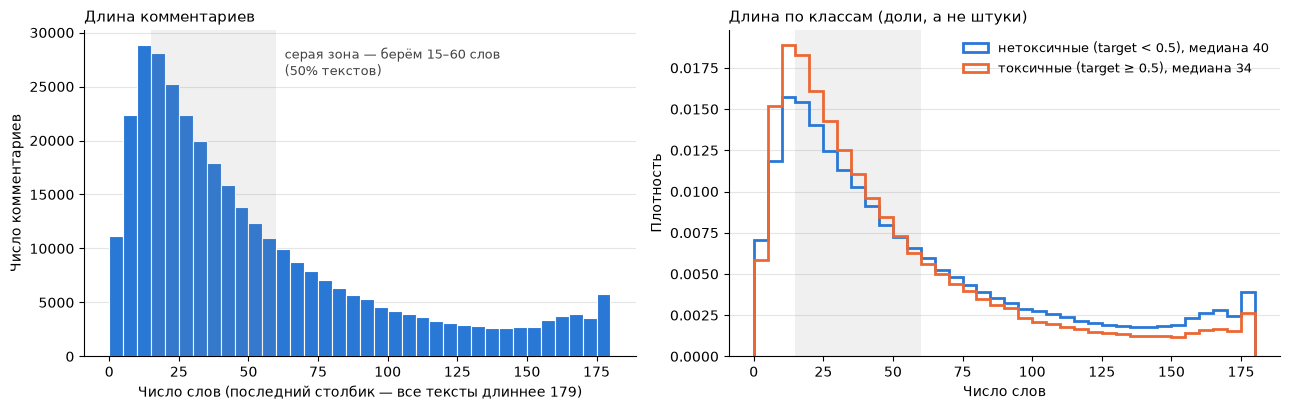

count    339399.0
mean         53.2
std          46.0
min           1.0
10%          10.0
25%          18.0
50%          38.0
75%          74.0
90%         129.0
99%         179.0
max         311.0
Name: n_words, dtype: float64


In [9]:
import matplotlib.pyplot as plt

# Распределение длины комментариев (в словах) среди текстов с >= MIN_ANNOTATORS разметчиками.
# Хвост длиннее 99-го перцентиля обрезаем, иначе основная масса сжимается у левого края.
x_max = int(df["n_words"].quantile(0.99))
bins = np.arange(0, x_max + 5, 5)
in_range = df["n_words"].between(MIN_WORDS, MAX_WORDS).mean()

BLUE, ORANGE = "#2a78d6", "#eb6834"
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

ax = axes[0]
ax.hist(df["n_words"].clip(upper=x_max), bins=bins, color=BLUE, edgecolor="white", linewidth=0.8)
ax.axvspan(MIN_WORDS, MAX_WORDS, color="#888888", alpha=0.12, lw=0)
ax.text(MAX_WORDS + 3, ax.get_ylim()[1] * 0.95,
        f"серая зона — берём {MIN_WORDS}–{MAX_WORDS} слов\n({in_range:.0%} текстов)", ha="left", va="top", fontsize=9, color="#444444")
ax.set_title("Длина комментариев", loc="left", fontsize=11)
ax.set_xlabel(f"Число слов (последний столбик — все тексты длиннее {x_max})")
ax.set_ylabel("Число комментариев")

ax = axes[1]
for lbl, name, color in [(0, "нетоксичные (target < 0.5)", BLUE), (1, "токсичные (target ≥ 0.5)", ORANGE)]:
    sub = df.loc[(df["target"] >= 0.5) == bool(lbl), "n_words"].clip(upper=x_max)
    ax.hist(sub, bins=bins, density=True, histtype="step", linewidth=2, color=color,
            label=f"{name}, медиана {int(sub.median())}")
ax.axvspan(MIN_WORDS, MAX_WORDS, color="#888888", alpha=0.12, lw=0)
ax.set_title("Длина по классам (доли, а не штуки)", loc="left", fontsize=11)
ax.set_xlabel("Число слов")
ax.set_ylabel("Плотность")
ax.legend(frameon=False, fontsize=9)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
    ax.set_axisbelow(True)
plt.tight_layout()
plt.show()
print(df["n_words"].describe(percentiles=[.1, .25, .5, .75, .9, .99]).round(1))

In [10]:
import tiktoken
enc = tiktoken.get_encoding("o200k_base")   # длина в токенах для матчинга соседей
clean["n_tokens"] = [len(enc.encode(t)) for t in clean["text"]]
# Ещё один фильтр мусора: нормальный английский текст — 1–2 токена на слово
clean["tok_per_word"] = clean["n_tokens"] / clean["n_words"]
before = len(clean)
clean = clean[clean["tok_per_word"] <= 2.5].copy()
print(f"убрано по токенам на слово: {before - len(clean)}")
clean["n_tokens"].describe()

убрано по токенам на слово: 32


count    165063.000000
mean         41.309991
std          15.886710
min          15.000000
25%          28.000000
50%          39.000000
75%          53.000000
max         134.000000
Name: n_tokens, dtype: float64

## Страты по человеческой разметке

| Страта | Условие | Роль |
|---|---|---|
| `clear_toxic` | `target >= 0.8` | соседи класса A, «очевидные» целевые |
| `clear_nontoxic` | `target == 0` | соседи класса B, «очевидные» целевые |
| `ambiguous` | `0.4 <= target <= 0.6` | «спорные» целевые (H2) |

Бинарная эталонная метка: `label = target >= 0.5`. Тексты с `target` между 0 и 0.4 и между 0.6 и 0.8 не используем, тк это «серая зона», которая размывает контраст.

In [11]:
def stratum(t):
    if t >= 0.8:
        return "clear_toxic"
    if t == 0:
        return "clear_nontoxic"
    if 0.4 <= t <= 0.6:
        return "ambiguous"
    return None

clean["stratum"] = clean["target"].map(stratum)
clean["label"] = (clean["target"] >= 0.5).astype(int)
clean = clean.dropna(subset=["stratum"])
clean["stratum"].value_counts()

stratum
ambiguous         51502
clear_toxic       11105
clear_nontoxic     1097
Name: count, dtype: int64

## Выборка: пул соседей + целевые тексты

- **Пул соседей**: `N_NEIGH` явно токсичных + `N_NEIGH` явно нетоксичных (по умолчанию 400+400 = 800, в рамках 700–1000).
- **Целевые**: 150 очевидных (75 токсичных + 75 нетоксичных) + 150 спорных. Целевые и соседи не пересекаются.

Это предварительный отбор; спорность «по модели» (H2, второй вариант) добавится после прогона одиночных запросов.

In [12]:
N_NEIGH = 400
N_CLEAR_TARGET_PER_CLASS = 75
N_AMBIG_TARGET = 150

def take(frame, n, seed=SEED):
    if len(frame) < n:
        raise ValueError(f"Не хватает текстов: нужно {n}, есть {len(frame)} — ослабьте фильтры")
    return frame.sample(n=n, random_state=seed)

tox = clean[clean["stratum"] == "clear_toxic"]
non = clean[clean["stratum"] == "clear_nontoxic"]
amb = clean[clean["stratum"] == "ambiguous"]

targets_clear = pd.concat([take(tox, N_CLEAR_TARGET_PER_CLASS), take(non, N_CLEAR_TARGET_PER_CLASS)])
targets_amb = take(amb, N_AMBIG_TARGET)
targets = pd.concat([targets_clear.assign(target_group="clear"),
                     targets_amb.assign(target_group="ambiguous")])

used = set(targets["id"])
neighbors = pd.concat([take(tox[~tox["id"].isin(used)], N_NEIGH),
                       take(non[~non["id"].isin(used)], N_NEIGH)])

assert not set(neighbors["id"]) & used
print(targets.groupby(["target_group", "label"]).size())
print(neighbors["label"].value_counts())

target_group  label
ambiguous     0        82
              1        68
clear         0        75
              1        75
dtype: int64
label
1    400
0    400
Name: count, dtype: int64


In [13]:
KEEP = ["id", "text", "target", "label", "stratum", "toxicity_annotator_count", "n_words", "n_tokens",
        "severe_toxicity", "obscene", "identity_attack", "insult", "threat", "sexual_explicit", "article_id"]
KEEP += [c for c in ["n_workers", "share_toxic"] if c in clean.columns]

targets[KEEP + ["target_group"]].to_parquet(DATA_PROC / "targets.parquet", index=False)
neighbors[KEEP].to_parquet(DATA_PROC / "neighbors_pool.parquet", index=False)
print("Сохранено в", DATA_PROC)

Сохранено в d:\statia\data\processed
